# ✨ **بِسْمِ ٱللَّٰهِ ٱلرَّحْمَٰنِ ٱلرَّحِيمِ** ✨


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Colab Notebooks/DL Project - Plant Disease Detection/dataset.zip'
extract_path = '/content/dataset_extracted'

# Unzip the dataset
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Successfully extracted dataset to {extract_path}")
else:
    print(f"Error: File not found at {zip_path}. Please make sure Google Drive is mounted and the path is correct.")

Successfully extracted dataset to /content/dataset_extracted


In [ ]:
# Explore the directory structure of the extracted files
def list_dir_structure(path, max_depth=2, current_depth=0):
    if current_depth > max_depth:
        return
    try:
        items = os.listdir(path)
        for item in sorted(items)[:15]: # Show up to 15 items per directory
            item_path = os.path.join(path, item)
            print("  " * current_depth + f"- {item}/" if os.path.isdir(item_path) else "  " * current_depth + f"- {item}")
            if os.path.isdir(item_path):
                list_dir_structure(item_path, max_depth, current_depth + 1)
        if len(items) > 15:
            print("  " * current_depth + f"... and {len(items) - 15} more items")
    except Exception as e:
        print(f"Error reading {path}: {e}")

list_dir_structure(extract_path)

- PlantVillage/
  - Pepper__bell___Bacterial_spot/
    - 0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG
    - 006adb74-934f-448f-a14f-62181742127b___JR_B.Spot 3395.JPG
    - 00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Spot 3132.JPG
    - 01613cd0-d3cd-4e96-945c-a312002037bf___JR_B.Spot 3262.JPG
    - 0169b9ac-07b9-4be1-8b85-da94481f05a4___NREC_B.Spot 9169.JPG
    - 018e494e-d2eb-468b-9d02-40219d9f4921___JR_B.Spot 9045.JPG
    - 01940b6d-7dea-4889-a7b8-a35f4e9bba34___NREC_B.Spot 9120.JPG
    - 01dfb88b-cd5a-420c-b163-51f5fe07b74d___JR_B.Spot 9091.JPG
    - 01ebc916-4793-40a3-b5e4-a32687e4fa3d___NREC_B.Spot 9125.JPG
    - 024623ab-be81-4d99-a653-c3be1495ce8e___JR_B.Spot 8889.JPG
    - 02baf62e-11e2-4dde-97fb-e369b57d55d3___JR_B.Spot 8971.JPG
    - 032aa7c4-0a95-4f09-b0bb-1242f4f32d82___NREC_B.Spot 1889.JPG
    - 03bb7042-3fd5-42e1-aa2c-d51d6843704c___JR_B.Spot 8925.JPG
    - 0448a226-3d3a-494d-a026-a92b048689c7___JR_B.Spot 8897.JPG
    - 0495b4d4-66a4-438c-862d-c483f08e4a95___

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

dataset_dir = '/content/dataset_extracted/PlantVillage'
if not os.path.exists(dataset_dir):
    # Fallback to the other folder in case extraction structure is nested differently
    dataset_dir = '/content/dataset_extracted/plantvillage/PlantVillage'

# Gather category information
categories = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]

data_summary = []
for category in categories:
    cat_path = os.path.join(dataset_dir, category)
    num_images = len([f for f in os.listdir(cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    data_summary.append({'Category': category, 'Image Count': num_images})

df = pd.DataFrame(data_summary).sort_values(by='Image Count', ascending=False)
print(f"Total classes: {len(df)}")
print(f"Total images: {df['Image Count'].sum()}")
print("\nClass Distribution:")
print(df.to_string(index=False))

Total classes: 15
Total images: 20638

Class Distribution:
                                   Category  Image Count
      Tomato__Tomato_YellowLeaf__Curl_Virus         3208
                      Tomato_Bacterial_spot         2127
                         Tomato_Late_blight         1909
                  Tomato_Septoria_leaf_spot         1771
Tomato_Spider_mites_Two_spotted_spider_mite         1676
                             Tomato_healthy         1591
                     Pepper__bell___healthy         1478
                        Tomato__Target_Spot         1404
                        Tomato_Early_blight         1000
                       Potato___Late_blight         1000
                      Potato___Early_blight         1000
              Pepper__bell___Bacterial_spot          997
                           Tomato_Leaf_Mold          952
                Tomato__Tomato_mosaic_virus          373
                           Potato___healthy          152


In [ ]:
# Visualize sample images from different categories
plt.figure(figsize=(15, 10))

sample_categories = random.sample(categories, min(6, len(categories)))
for i, category in enumerate(sample_categories):
    cat_path = os.path.join(dataset_dir, category)
    images = [f for f in os.listdir(cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if not images:
        continue

    random_img_name = random.choice(images)
    img_path = os.path.join(cat_path, random_img_name)

    img = Image.open(img_path)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(category.replace('___', ' - '), fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import shutil

reduced_dataset_dir = '/content/dataset_reduced'
os.makedirs(reduced_dataset_dir, exist_ok=True)

# We will focus on these 4 major Tomato classes to build an accurate, balanced model
selected_classes = [
    'Tomato_healthy',
    'Tomato_Bacterial_spot',
    'Tomato_Early_blight',
    'Tomato_Late_blight'
]

max_images_per_class = 1000  # Cap images per class to ensure class balance

for category in selected_classes:
    src_cat_path = os.path.join(dataset_dir, category)
    dest_cat_path = os.path.join(reduced_dataset_dir, category)
    os.makedirs(dest_cat_path, exist_ok=True)

    images = [f for f in os.listdir(src_cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    # Keep a consistent sample limit
    sampled_images = random.sample(images, min(max_images_per_class, len(images)))

    print(f"Copying {len(sampled_images)} images for class: {category}")
    for img_name in sampled_images:
        shutil.copy(
            os.path.join(src_cat_path, img_name),
            os.path.join(dest_cat_path, img_name)
        )

print("\nDataset reduction complete! Ready for custom CNN and Transfer Learning.")

Copying 1000 images for class: Tomato_healthy
Copying 1000 images for class: Tomato_Bacterial_spot
Copying 1000 images for class: Tomato_Early_blight
Copying 1000 images for class: Tomato_Late_blight

Dataset reduction complete! Ready for custom CNN and Transfer Learning.


In [ ]:
import os
import numpy as np
import cv2

# Create directory for the 5th class: Not_Leaf
reduced_dataset_dir = '/content/dataset_reduced'
not_leaf_dir = os.path.join(reduced_dataset_dir, 'Not_Leaf')
os.makedirs(not_leaf_dir, exist_ok=True)

print("Generating 1,000 diverse background/non-leaf images for the 'Not_Leaf' class...")

# Programmatically generate high-quality abstract noise, geometric patterns, solid colors, and textures
for i in range(1000):
    img_size = (224, 224, 3)
    pattern_type = i % 5

    if pattern_type == 0:
        # Random Solid Color / Gradient
        color = np.random.randint(0, 256, size=3, dtype=np.uint8)
        img = np.full(img_size, color, dtype=np.uint8)
    elif pattern_type == 1:
        # Random Noise
        img = np.random.randint(0, 256, size=img_size, dtype=np.uint8)
    elif pattern_type == 2:
        # Checkerboard / Grid patterns
        img = np.zeros(img_size, dtype=np.uint8)
        grid_size = np.random.choice([8, 16, 28, 32])
        for r in range(0, 224, grid_size):
            for c in range(0, 224, grid_size):
                if (r // grid_size + c // grid_size) % 2 == 0:
                    img[r:r+grid_size, c:c+grid_size] = np.random.randint(0, 256, size=3)
    elif pattern_type == 3:
        # Random geometric shapes (circles, lines, rectangles)
        img = np.full(img_size, 255, dtype=np.uint8)
        for _ in range(15):
            color = tuple(map(int, np.random.randint(0, 256, size=3)))
            shape = np.random.choice(['circle', 'rect', 'line'])
            p1 = tuple(map(int, np.random.randint(0, 224, size=2)))
            p2 = tuple(map(int, np.random.randint(0, 224, size=2)))
            if shape == 'circle':
                cv2.circle(img, p1, int(np.random.randint(10, 80)), color, -1)
            elif shape == 'rect':
                cv2.rectangle(img, p1, p2, color, -1)
            else:
                cv2.line(img, p1, p2, color, int(np.random.randint(1, 10)))
    else:
        # Sine wave / wave patterns
        img = np.zeros(img_size, dtype=np.uint8)
        x = np.arange(224)
        y = np.sin(x / 10.0) * 50 + 112
        for channel in range(3):
            val = np.random.randint(50, 200)
            for col in range(224):
                row = int(np.clip(y[col] + np.random.randint(-10, 11), 0, 223))
                img[row:, col, channel] = val

    # Save the generated non-leaf image
    img_name = f"not_leaf_{i:04d}.jpg"
    cv2.imwrite(os.path.join(not_leaf_dir, img_name), img)

print(f"Successfully generated and added {len(os.listdir(not_leaf_dir))} images to: {not_leaf_dir}")

Generating 1,000 diverse background/non-leaf images for the 'Not_Leaf' class...
Successfully generated and added 1000 images to: /content/dataset_reduced/Not_Leaf


In [ ]:
import os

# Let's verify our 5 classes inside the reduced dataset directory
reduced_dataset_dir = '/content/dataset_reduced'
classes = sorted(os.listdir(reduced_dataset_dir))
print("--- 5-Class Dataset Verification ---")
print("Classes found:", classes)

for cls in classes:
    cls_path = os.path.join(reduced_dataset_dir, cls)
    if os.path.isdir(cls_path):
        num_imgs = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        print(f"- {cls}: {num_imgs} images")

--- 5-Class Dataset Verification ---
Classes found: ['Not_Leaf', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_healthy']
- Not_Leaf: 1000 images
- Tomato_Bacterial_spot: 1000 images
- Tomato_Early_blight: 1000 images
- Tomato_Late_blight: 1000 images
- Tomato_healthy: 1000 images


In [ ]:
import os
import shutil
import random

# Ensure the selected 4 tomato classes are copied over alongside Not_Leaf
reduced_dataset_dir = '/content/dataset_reduced'
dataset_dir = '/content/dataset_extracted/PlantVillage'
if not os.path.exists(dataset_dir):
    dataset_dir = '/content/dataset_extracted/plantvillage/PlantVillage'

selected_classes = [
    'Tomato_healthy',
    'Tomato_Bacterial_spot',
    'Tomato_Early_blight',
    'Tomato_Late_blight'
]

max_images_per_class = 1000

for category in selected_classes:
    src_cat_path = os.path.join(dataset_dir, category)
    dest_cat_path = os.path.join(reduced_dataset_dir, category)

    # Only copy if the class folder is not already populated
    if not os.path.exists(dest_cat_path) or len(os.listdir(dest_cat_path)) < 500:
        os.makedirs(dest_cat_path, exist_ok=True)
        images = [f for f in os.listdir(src_cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        sampled_images = random.sample(images, min(max_images_per_class, len(images)))
        print(f"Copying {len(sampled_images)} images for class: {category}")
        for img_name in sampled_images:
            shutil.copy(
                os.path.join(src_cat_path, img_name),
                os.path.join(dest_cat_path, img_name)
            )

# Update classes list and verify dataset contents
classes_in_reduced = sorted(os.listdir(reduced_dataset_dir))
print("\n--- Verification of 5 Classes in training dataset ---")
print("Current categories in our training dataset:", classes_in_reduced)
for category in classes_in_reduced:
    cat_path = os.path.join(reduced_dataset_dir, category)
    print(f"- {category}: {len(os.listdir(cat_path))} images")

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Set random seed for reproducibility
torch.manual_seed(42)

# Define paths
data_dir = '/content/dataset_reduced'

# Image transformations (Resizing to 224x224)
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load original datasets (Now contains 5 classes: 4 Tomato + 1 Not_Leaf)
full_dataset = datasets.ImageFolder(root=data_dir)
print("Detected classes:", full_dataset.classes)

# Split into 70% Train, 15% Val, 15% Test
total_size = len(full_dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_set, val_set, test_set = random_split(full_dataset, [train_size, val_size, test_size])

# Apply specific transforms
class TransformedDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedDataset(train_set, transform=transform_train)
val_dataset = TransformedDataset(val_set, transform=transform_val_test)
test_dataset = TransformedDataset(test_set, transform=transform_val_test)

# Data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Data splitting completed successfully with 5 classes!")
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Testing set size: {len(test_dataset)}")

Detected classes: ['Not_Leaf', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_healthy']
Data splitting completed successfully with 5 classes!
Training set size: 3500
Validation set size: 750
Testing set size: 750


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CustomPlantCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(CustomPlantCNN, self).__init__()
        # Convolutional Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        # Convolutional Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        # Convolutional Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.25)

        # Linear layers (224 -> 112 -> 56 -> 28)
        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.bn4 = nn.BatchNorm1d(512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.dropout(x)

        x = x.view(-1, 128 * 28 * 28)
        x = F.relu(self.bn4(self.fc1(x)))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
custom_model = CustomPlantCNN(num_classes=5).to(device)
print(custom_model)

CustomPlantCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=100352, out_features=512, bias=True)
  (bn4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=512, out_features=5, bias=True)
)


In [ ]:
import torch.optim as optim
import time

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_model.parameters(), lr=0.001)

def train_model(model, train_loader, val_loader, criterion, optimizer, save_path, epochs=10):
    best_val_acc = 0.0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        corrects = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_acc = corrects.double() / total

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_corrects = 0
        val_total = 0

        with torch.no_grad():
            for val_inputs, val_labels in val_loader:
                val_inputs, val_labels = val_inputs.to(device), val_labels.to(device)
                val_outputs = model(val_inputs)
                val_loss_val = criterion(val_outputs, val_labels)

                val_loss += val_loss_val.item() * val_inputs.size(0)
                _, val_preds = torch.max(val_outputs, 1)
                val_corrects += torch.sum(val_preds == val_labels.data)
                val_total += val_labels.size(0)

        val_epoch_loss = val_loss / val_total
        val_epoch_acc = val_corrects.double() / val_total

        history['train_loss'].append(epoch_loss)
        history['train_acc'].append(epoch_acc.item())
        history['val_loss'].append(val_epoch_loss)
        history['val_acc'].append(val_epoch_acc.item())

        duration = time.time() - start_time
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | Val Loss: {val_epoch_loss:.4f} Acc: {val_epoch_acc:.4f} | Time: {duration:.1f}s")

        if val_epoch_acc > best_val_acc:
            best_val_acc = val_epoch_acc
            torch.save(model.state_dict(), save_path)
            print(f"--> Saved best model weights to: {save_path}")

    return history

print("Training Custom CNN...")
custom_history = train_model(custom_model, train_loader, val_loader, criterion, optimizer, save_path='best_custom_cnn.pth', epochs=10)

Training Custom CNN...
Epoch 1/10 | Train Loss: 0.5132 Acc: 0.8034 | Val Loss: 0.2455 Acc: 0.8947 | Time: 16.0s
--> Saved best model weights to: best_custom_cnn.pth
Epoch 2/10 | Train Loss: 0.2782 Acc: 0.9003 | Val Loss: 0.1585 Acc: 0.9560 | Time: 13.4s
--> Saved best model weights to: best_custom_cnn.pth
Epoch 3/10 | Train Loss: 0.2028 Acc: 0.9197 | Val Loss: 0.2071 Acc: 0.9280 | Time: 13.4s
Epoch 4/10 | Train Loss: 0.1840 Acc: 0.9369 | Val Loss: 0.1540 Acc: 0.9480 | Time: 14.2s
Epoch 5/10 | Train Loss: 0.1701 Acc: 0.9366 | Val Loss: 0.1260 Acc: 0.9573 | Time: 13.7s
--> Saved best model weights to: best_custom_cnn.pth
Epoch 6/10 | Train Loss: 0.1394 Acc: 0.9537 | Val Loss: 0.1205 Acc: 0.9600 | Time: 13.4s
--> Saved best model weights to: best_custom_cnn.pth
Epoch 7/10 | Train Loss: 0.1109 Acc: 0.9611 | Val Loss: 0.0952 Acc: 0.9733 | Time: 13.7s
--> Saved best model weights to: best_custom_cnn.pth
Epoch 8/10 | Train Loss: 0.1109 Acc: 0.9597 | Val Loss: 0.1001 Acc: 0.9613 | Time: 14.0s


In [ ]:
from torchvision import models

# Load pre-trained ResNet18
pretrained_model = models.resnet18(pretrained=True)

# Freeze model weights so we only train the new final layer
for param in pretrained_model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer with a fresh one for our 5 target classes
num_ftrs = pretrained_model.fc.in_features
pretrained_model.fc = nn.Linear(num_ftrs, 5)

# Transfer to GPU
pretrained_model = pretrained_model.to(device)
print(pretrained_model.fc)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


Linear(in_features=512, out_features=5, bias=True)


In [ ]:
# Optimizer and loss for the pre-trained model (only training the parameters of the FC layer)
optimizer_pretrained = optim.Adam(pretrained_model.fc.parameters(), lr=0.001)
criterion_pretrained = nn.CrossEntropyLoss()

print("Training Pre-trained ResNet18...")
pretrained_history = train_model(
    pretrained_model,
    train_loader,
    val_loader,
    criterion_pretrained,
    optimizer_pretrained,
    save_path='best_resnet18.pth',
    epochs=10
)

Training Pre-trained ResNet18...
Epoch 1/10 | Train Loss: 0.7293 Acc: 0.7683 | Val Loss: 0.4025 Acc: 0.9093 | Time: 12.5s
--> Saved best model weights to: best_resnet18.pth
Epoch 2/10 | Train Loss: 0.3496 Acc: 0.8994 | Val Loss: 0.3000 Acc: 0.9133 | Time: 11.2s
--> Saved best model weights to: best_resnet18.pth
Epoch 3/10 | Train Loss: 0.2701 Acc: 0.9177 | Val Loss: 0.2238 Acc: 0.9400 | Time: 11.1s
--> Saved best model weights to: best_resnet18.pth
Epoch 4/10 | Train Loss: 0.2397 Acc: 0.9266 | Val Loss: 0.2022 Acc: 0.9480 | Time: 11.1s
--> Saved best model weights to: best_resnet18.pth
Epoch 5/10 | Train Loss: 0.2155 Acc: 0.9323 | Val Loss: 0.1827 Acc: 0.9507 | Time: 11.1s
--> Saved best model weights to: best_resnet18.pth
Epoch 6/10 | Train Loss: 0.2083 Acc: 0.9306 | Val Loss: 0.1743 Acc: 0.9533 | Time: 11.3s
--> Saved best model weights to: best_resnet18.pth
Epoch 7/10 | Train Loss: 0.1895 Acc: 0.9377 | Val Loss: 0.1756 Acc: 0.9493 | Time: 11.4s
Epoch 8/10 | Train Loss: 0.1678 Acc: 0

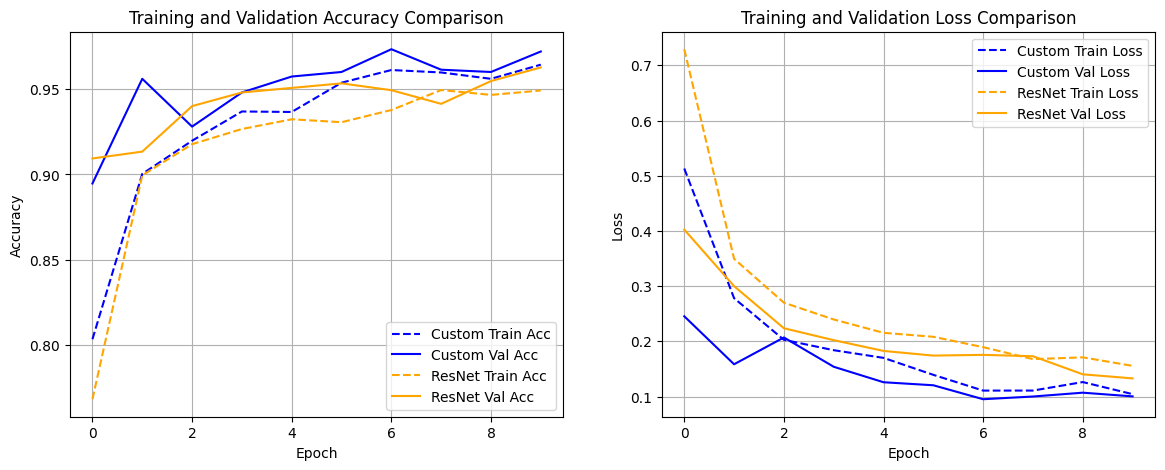

In [ ]:
import matplotlib.pyplot as plt

# Plot Accuracies
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(custom_history['train_acc'], label='Custom Train Acc', color='blue', linestyle='--')
plt.plot(custom_history['val_acc'], label='Custom Val Acc', color='blue')
plt.plot(pretrained_history['train_acc'], label='ResNet Train Acc', color='orange', linestyle='--')
plt.plot(pretrained_history['val_acc'], label='ResNet Val Acc', color='orange')
plt.title('Training and Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Losses
plt.subplot(1, 2, 2)
plt.plot(custom_history['train_loss'], label='Custom Train Loss', color='blue', linestyle='--')
plt.plot(custom_history['val_loss'], label='Custom Val Loss', color='blue')
plt.plot(pretrained_history['train_loss'], label='ResNet Train Loss', color='orange', linestyle='--')
plt.plot(pretrained_history['val_loss'], label='ResNet Val Loss', color='orange')
plt.title('Training and Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def evaluate_model(model, test_loader, model_name):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels.data)
            total += labels.size(0)

    accuracy = correct.double() / total
    print(f"{model_name} Test Accuracy: {accuracy:.4f}")
    return accuracy.item()

print("Evaluating Models on Unseen Test Dataset...")
custom_test_acc = evaluate_model(custom_model, test_loader, "Custom CNN")
resnet_test_acc = evaluate_model(pretrained_model, test_loader, "Pre-trained ResNet18")

Evaluating Models on Unseen Test Dataset...
Custom CNN Test Accuracy: 0.9653
Pre-trained ResNet18 Test Accuracy: 0.9413


### 💾 Step 1: Backup both models to Google Drive

In [ ]:
import os
import shutil
from google.colab import drive

# Ensure drive is mounted
drive.mount('/content/drive', force_remount=True)

# Define dedicated output directory on Drive
drive_output_dir = '/content/drive/MyDrive/Colab Notebooks/DL Project - Plant Disease Detection/Organized_Outputs'
os.makedirs(drive_output_dir, exist_ok=True)

# 1. Copy Custom CNN model
custom_cnn_dest = os.path.join(drive_output_dir, 'best_custom_cnn_5class.pth')
shutil.copy('/content/best_custom_cnn.pth', custom_cnn_dest)
print(f"✓ Saved Custom CNN weights (5-class) to Drive: {custom_cnn_dest}")

# 2. Copy ResNet18 model
resnet_dest = os.path.join(drive_output_dir, 'best_resnet18_5class.pth')
shutil.copy('/content/best_resnet18.pth', resnet_dest)
print(f"✓ Saved ResNet18 weights (5-class) to Drive: {resnet_dest}")

Mounted at /content/drive
✓ Saved Custom CNN weights (5-class) to Drive: /content/drive/MyDrive/Colab Notebooks/DL Project - Plant Disease Detection/Organized_Outputs/best_custom_cnn_5class.pth
✓ Saved ResNet18 weights (5-class) to Drive: /content/drive/MyDrive/Colab Notebooks/DL Project - Plant Disease Detection/Organized_Outputs/best_resnet18_5class.pth
